## Read embeddings

In [1]:
import pandas as pd
MODELS_DESCRIPTIONS = {
    "mix_of_alleles_balanced":
    {
        "alleles": ['HLA-A*01:01', 'HLA-A*03:01', 'HLA-A*02:01'],
        "path": "experiment_results/alleles_with_groups_balanced/",
        "states": 25,
        "params_string": "5-min_iters",
        "target_lengths": [9, 10]
    },
    
    "mix_of_alleles":
    {
        "path": "experiment_results/alleles_with_groups/",
        "states": 25,
        "params_string": "5-min_iters",
        "alleles": ['HLA-A*01:01', 'HLA-A*03:01'],
        "target_lengths": [9, 10]
    },

}

In [2]:
selected_model = MODELS_DESCRIPTIONS["mix_of_alleles"]

selected_alleles = selected_model['alleles']
states = selected_model['states']
TARGET_LENGTHS = selected_model['target_lengths']
selected_combination = "+".join(selected_alleles).replace('-', '_').replace('*', '_').replace(':', '_')
selected_model_split = 0 # should match to data split (if original train/test used) in order to have true test case
selected_model_run = 0
target_length_string = "-".join([str(l) for l in TARGET_LENGTHS])

In [3]:
mixed_model_bw =f'{selected_model_run}_run-{target_length_string}-{states}-st-baum-welch-alg-5-min_iters_model-{selected_combination}-{selected_model_split}'
mixed_model_bwv = f'{selected_model_run}_run-{target_length_string}-{states}-st-baum-welch-alg-5-min_iters_model-{selected_combination}-{selected_model_split}_plus_viterbi'
mixed_model_v = f'{selected_model_run}_run-{target_length_string}-{states}-st-viterbi-alg-5-min_iters_model-{selected_combination}-{selected_model_split}'

name_to_model_root = dict()
name_to_model_root[mixed_model_bw] = selected_model['path']
name_to_model_root[mixed_model_bwv] = selected_model['path']
name_to_model_root[mixed_model_v] = selected_model['path']

In [4]:
def load_scored_netmhc_umaps(model, model_type='bw'):
    print(f"model {model}")
    TARGET_PATH_TO_FILES = name_to_model_root[model] + model
    # have scores for each allele
    
    per_allele_scoring_train_df = dict()
    per_allele_scoring_test_df = dict()

    for allele_name in selected_alleles:
        target_allele_name = allele_name.replace('-', '_').replace('*', '_').replace(':', '_')
        # Train 
        train_df =  pd.read_csv("{}/NetMHC_train_{}_predictions_allele_{}.csv".format(TARGET_PATH_TO_FILES,model_type, target_allele_name),sep=";", index_col=0)
        # Test 
        test_df =  pd.read_csv("{}/NetMHC_test_{}_predictions_allele_{}.csv".format(TARGET_PATH_TO_FILES,model_type, target_allele_name),sep=";", index_col=0)    
    # paths_df['path'] = paths_df['path'].apply(pd.eval)
    # paths_df['path'] = paths_df['path'].astype(list)
        per_allele_scoring_train_df[allele_name] = train_df
        per_allele_scoring_test_df[allele_name] = test_df
    return  per_allele_scoring_train_df, per_allele_scoring_test_df


In [5]:
%%time




per_model_type_perscoringallele_train_embeddings = dict()
per_model_type_perscoringallele_test_embeddings = dict()
# BW
perscoring_train, perscoring_test = load_scored_netmhc_umaps(mixed_model_bw, model_type='bw')
per_model_type_perscoringallele_train_embeddings['bw'] = perscoring_train
per_model_type_perscoringallele_test_embeddings['bw'] = perscoring_test
# BWV
perscoring_train, perscoring_test = load_scored_netmhc_umaps(mixed_model_bwv, model_type='bwv')
per_model_type_perscoringallele_train_embeddings['bwv'] = perscoring_train
per_model_type_perscoringallele_test_embeddings['bwv'] = perscoring_test
# V
perscoring_train, perscoring_test = load_scored_netmhc_umaps(mixed_model_v, model_type='v')
per_model_type_perscoringallele_train_embeddings['v'] = perscoring_train
per_model_type_perscoringallele_test_embeddings['v'] = perscoring_test

model 0_run-9-10-25-st-baum-welch-alg-5-min_iters_model-HLA_A_01_01+HLA_A_03_01-0
model 0_run-9-10-25-st-baum-welch-alg-5-min_iters_model-HLA_A_01_01+HLA_A_03_01-0_plus_viterbi
model 0_run-9-10-25-st-viterbi-alg-5-min_iters_model-HLA_A_01_01+HLA_A_03_01-0
Wall time: 502 ms


In [6]:
per_model_type_perscoringallele_train_embeddings['v'][selected_alleles[1]]

,0,1,allele,dataset,length,peptide,source_sequence_name,netMHC-3.4_score,netMHC-3.4_affinity,netMHC-3.4_percentile_rank,...,netMHCpan-4.1_score_ba,netMHCpan-4.1_score_el,netMHCpan-4.1_affinity,netMHCpan-4.1_percentile_rank_ba,netMHCpan-4.1_percentile_rank_el,netMHCIIpan-4.0_score_ba,netMHCIIpan-4.0_score_el,netMHCIIpan-4.0_affinity,netMHCIIpan-4.0_percentile_rank_ba,netMHCIIpan-4.0_percentile_rank_el
0,5.450842,0.864987,HLA-A*01:01,Train_db,9,SFDIQLTSV,seq0,0.072,23044.0,NaN,...,0.049130,0.000446,29383.90,33.423,19.123,NaN,NaN,NaN,NaN,NaN
1,2.055700,1.715298,HLA-A*01:01,Train_db,9,TTEILRSML,seq1,0.075,22202.0,NaN,...,0.039371,0.000133,32656.29,43.448,30.455,NaN,NaN,NaN,NaN,NaN
2,4.524084,2.591722,HLA-A*03:01,Train_db,10,ALNDTWKMEK,seq2,0.550,129.0,NaN,...,0.667700,0.856369,36.43,0.141,0.074,NaN,NaN,NaN,NaN,NaN
3,4.711285,2.133525,HLA-A*03:01,Train_db,10,ALAAAAAAAK,seq3,0.666,36.0,NaN,...,0.597612,0.361055,77.77,0.304,0.714,NaN,NaN,NaN,NaN,NaN
4,1.758685,1.481272,HLA-A*01:01,Train_db,9,LYDKDAVYV,seq4,0.069,23591.0,NaN,...,0.033744,0.000260,34706.28,51.038,23.552,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
13331,4.822346,5.822981,HLA-A*03:01,Train_db,9,FIFQSSMTK,seq13331,0.696,26.0,NaN,...,0.686432,0.880661,29.75,0.112,0.059,NaN,NaN,NaN,NaN,NaN
13332,9.838545,3.965494,HLA-A*03:01,Train_db,9,QLYKEQLAK,seq13332,0.693,27.0,NaN,...,0.707560,0.944811,23.67,0.076,0.021,NaN,NaN,NaN,NaN,NaN
13333,9.514293,4.696215,HLA-A*03:01,Train_db,9,LLNRPLWAK,seq13333,0.685,30.0,NaN,...,0.693875,0.793779,27.45,0.102,0.132,NaN,NaN,NaN,NaN,NaN
13334,9.151677,4.881634,HLA-A*03:01,Train_db,9,KVPVVLLKK,seq13334,0.604,72.0,NaN,...,0.585287,0.873540,88.86,0.344,0.064,NaN,NaN,NaN,NaN,NaN


In [7]:
per_model_type_perscoringallele_train_embeddings['v'][selected_alleles[0]]

,0,1,allele,dataset,length,peptide,source_sequence_name,netMHC-3.4_score,netMHC-3.4_affinity,netMHC-3.4_percentile_rank,...,netMHCpan-4.1_score_ba,netMHCpan-4.1_score_el,netMHCpan-4.1_affinity,netMHCpan-4.1_percentile_rank_ba,netMHCpan-4.1_percentile_rank_el,netMHCIIpan-4.0_score_ba,netMHCIIpan-4.0_score_el,netMHCIIpan-4.0_affinity,netMHCIIpan-4.0_percentile_rank_ba,netMHCIIpan-4.0_percentile_rank_el
0,5.450842,0.864987,HLA-A*01:01,Train_db,9,SFDIQLTSV,seq0,0.087,19528.0,NaN,...,0.107346,0.016110,15651.44,5.825,3.746,NaN,NaN,NaN,NaN,NaN
1,2.055700,1.715298,HLA-A*01:01,Train_db,9,TTEILRSML,seq1,0.131,12158.0,NaN,...,0.158139,0.048042,9033.99,2.716,2.031,NaN,NaN,NaN,NaN,NaN
2,4.524084,2.591722,HLA-A*03:01,Train_db,10,ALNDTWKMEK,seq2,0.079,21205.0,NaN,...,0.100008,0.006835,16944.76,6.624,6.078,NaN,NaN,NaN,NaN,NaN
3,4.711285,2.133525,HLA-A*03:01,Train_db,10,ALAAAAAAAK,seq3,0.079,21262.0,NaN,...,0.054600,0.000421,27695.31,20.777,30.393,NaN,NaN,NaN,NaN,NaN
4,1.758685,1.481272,HLA-A*01:01,Train_db,9,LYDKDAVYV,seq4,0.085,19831.0,NaN,...,0.093010,0.012319,18277.58,7.578,4.344,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
13331,4.822346,5.822981,HLA-A*03:01,Train_db,9,FIFQSSMTK,seq13331,0.081,20745.0,NaN,...,0.080434,0.004401,20941.75,10.018,7.786,NaN,NaN,NaN,NaN,NaN
13332,9.838545,3.965494,HLA-A*03:01,Train_db,9,QLYKEQLAK,seq13332,0.078,21560.0,NaN,...,0.049110,0.003064,29390.27,25.118,9.645,NaN,NaN,NaN,NaN,NaN
13333,9.514293,4.696215,HLA-A*03:01,Train_db,9,LLNRPLWAK,seq13333,0.078,21389.0,NaN,...,0.081192,0.002048,20770.70,9.844,12.259,NaN,NaN,NaN,NaN,NaN
13334,9.151677,4.881634,HLA-A*03:01,Train_db,9,KVPVVLLKK,seq13334,0.075,22149.0,NaN,...,0.044215,0.004789,30988.81,30.010,7.402,NaN,NaN,NaN,NaN,NaN


# Color umap using predictors

In [42]:
import umap
from sklearn.preprocessing import StandardScaler
from collections import defaultdict
import matplotlib.pyplot as plt
import seaborn as sns



def define_pallete(df, hue_column):
    unique_hue_values = sorted(df[hue_column].unique())
    if len(unique_hue_values) <= 4: 
        source_pallete = sns.color_palette("hls", len(unique_hue_values))
        colors ={hue_value: source_pallete[i] for i, hue_value in enumerate(unique_hue_values)}
    else:
        colors = sns.color_palette("rocket_r", as_cmap=True) #sns.color_palette("viridis", as_cmap=True)

    return colors

def make_scatter_plot_sns(source_df, title, colors=None, hue_column='dataset' ):
    source_df = source_df.sample(frac=1)
    fig,ax = plt.subplots(figsize=(12, 10))
    sns.set_theme(style="dark")
    
    if colors is None:
        colors = define_pallete(source_df,hue_column )
    ax = sns.scatterplot(data=source_df, x=source_df.columns[0], y=source_df.columns[1], hue=hue_column,ax=ax, picker=4, s=10,
                         palette=colors)
    ax.set_title(title)
    return fig


# Make plots

model bw
model bwv
model v


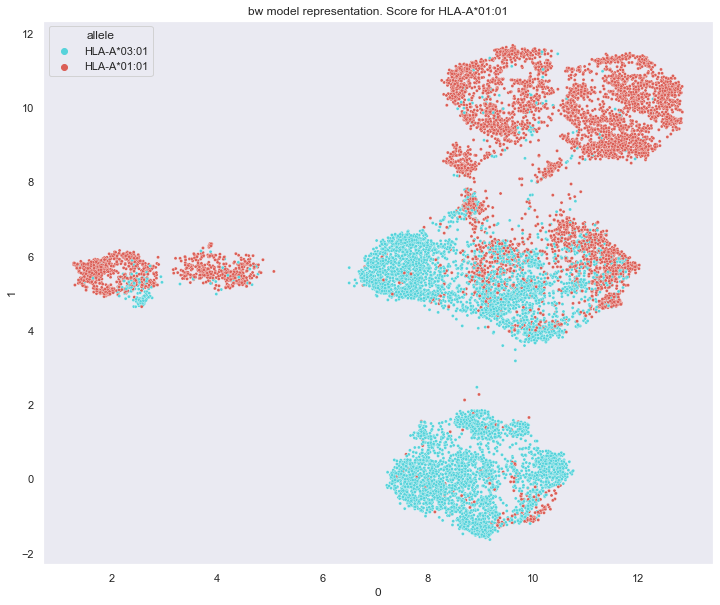

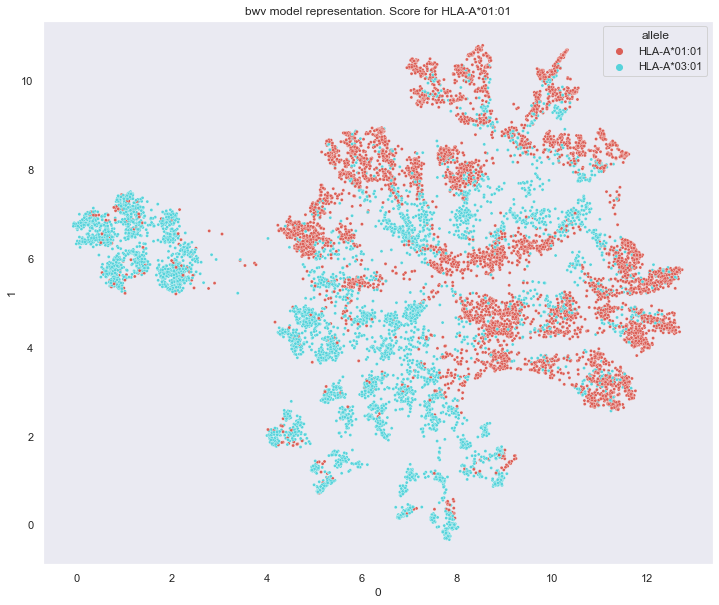

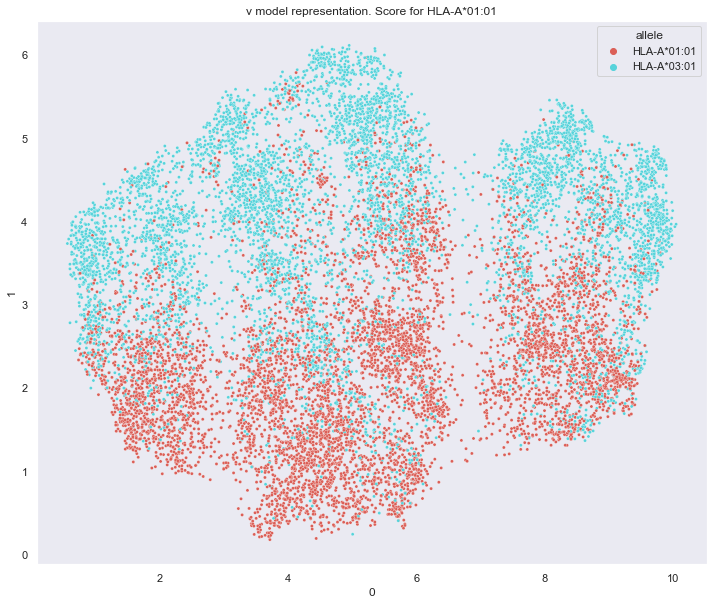

In [43]:
PREDICTOR_ALLELE = selected_alleles[0]

for model, perscoringallele_train_embeddings in per_model_type_perscoringallele_train_embeddings.items():
    print(f"model {model}")

    train_df = perscoringallele_train_embeddings[PREDICTOR_ALLELE]
    test_df = per_model_type_perscoringallele_test_embeddings[model][PREDICTOR_ALLELE]
    
    fig = make_scatter_plot_sns(train_df, title=f"{model} model representation. Score for {PREDICTOR_ALLELE}", hue_column='allele')

In [44]:
per_model_type_perscoringallele_train_embeddings['bw'][selected_alleles[0]].columns

Index(['0', '1', 'allele', 'dataset', 'length', 'peptide',
       'source_sequence_name', 'netMHC-3.4_score', 'netMHC-3.4_affinity',
       'netMHC-3.4_percentile_rank', 'netMHC-4.0_score', 'netMHC-4.0_affinity',
       'netMHC-4.0_percentile_rank', 'netMHCpan-4.1_score_ba',
       'netMHCpan-4.1_score_el', 'netMHCpan-4.1_affinity',
       'netMHCpan-4.1_percentile_rank_ba', 'netMHCpan-4.1_percentile_rank_el',
       'netMHCIIpan-4.0_score_ba', 'netMHCIIpan-4.0_score_el',
       'netMHCIIpan-4.0_affinity', 'netMHCIIpan-4.0_percentile_rank_ba',
       'netMHCIIpan-4.0_percentile_rank_el'],
      dtype='object')

In [50]:
score = 'netMHCpan-4.1_score_el'

model bw
model bwv
model v


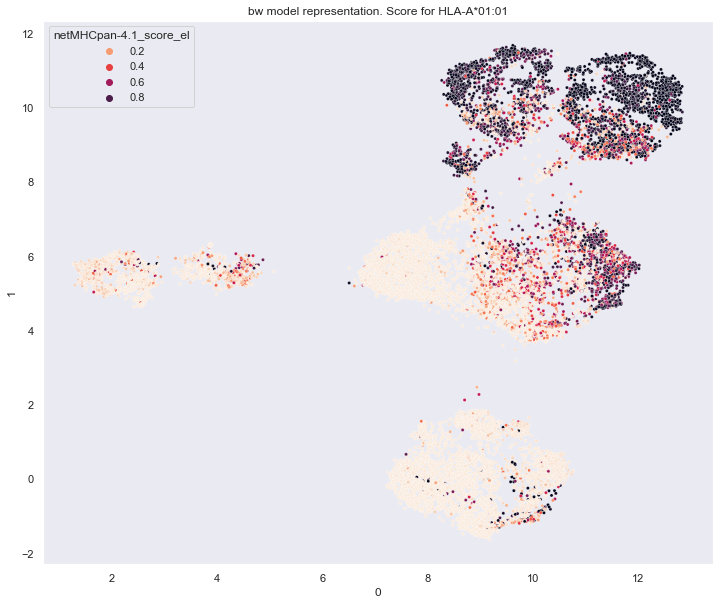

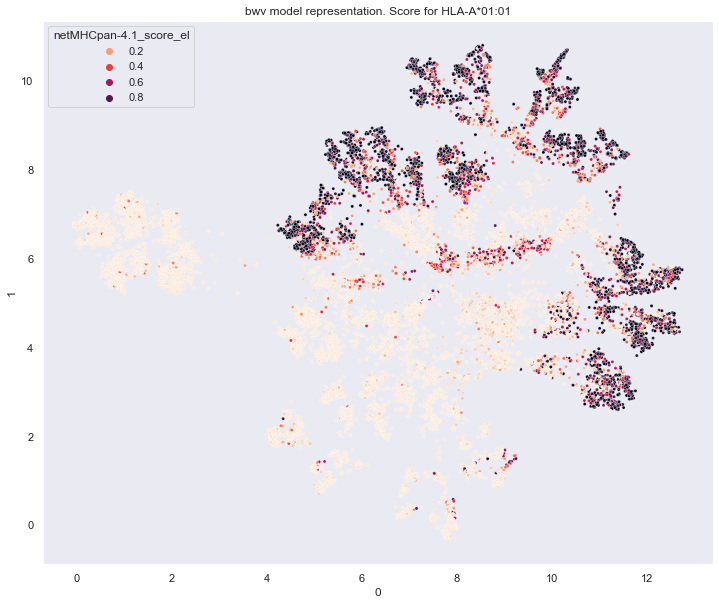

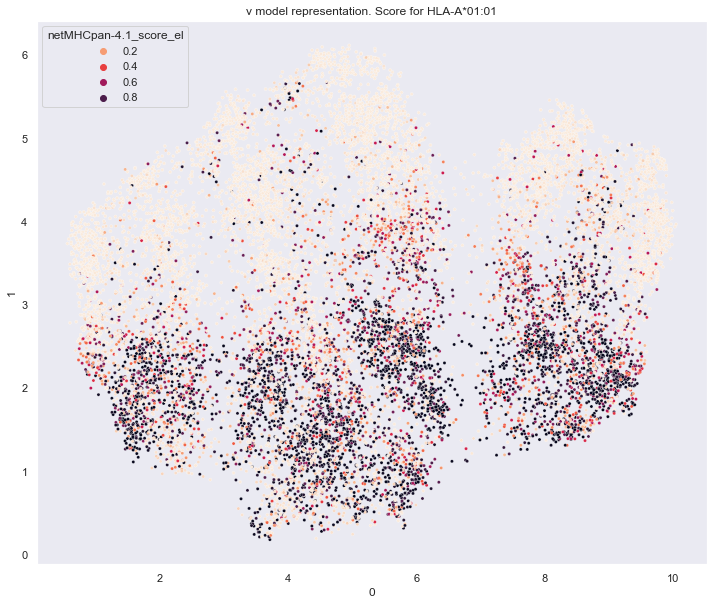

In [51]:
PREDICTOR_ALLELE = selected_alleles[0]
for model, perscoringallele_train_embeddings in per_model_type_perscoringallele_train_embeddings.items():
    print(f"model {model}")

    train_df = perscoringallele_train_embeddings[PREDICTOR_ALLELE]
    test_df = per_model_type_perscoringallele_test_embeddings[model][PREDICTOR_ALLELE]
    
    fig = make_scatter_plot_sns(train_df, title=f"{model} model representation. Score for {PREDICTOR_ALLELE}", hue_column=score)

model bw
model bwv
model v


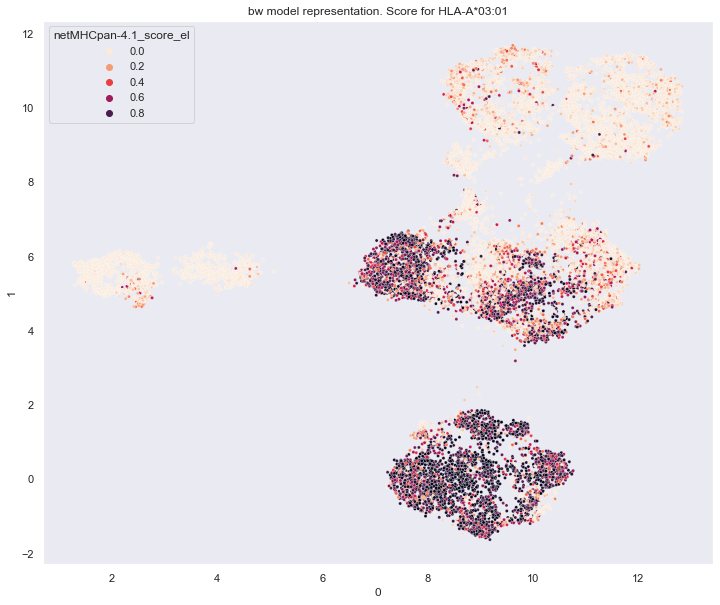

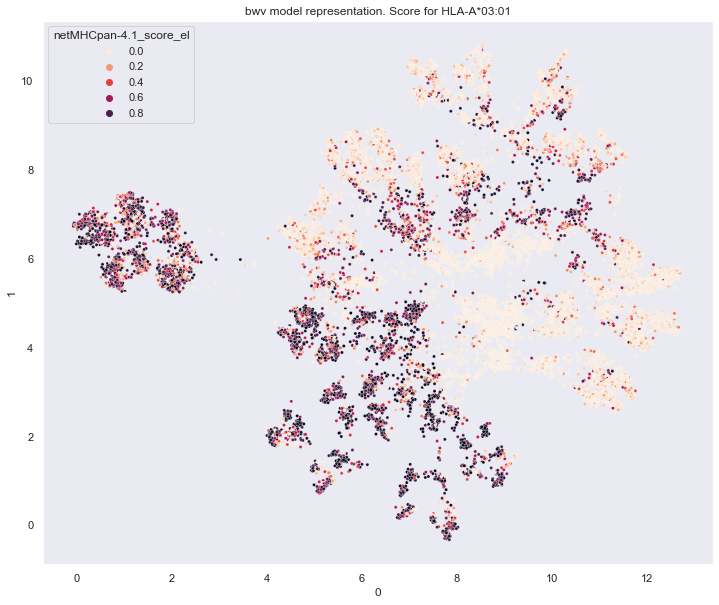

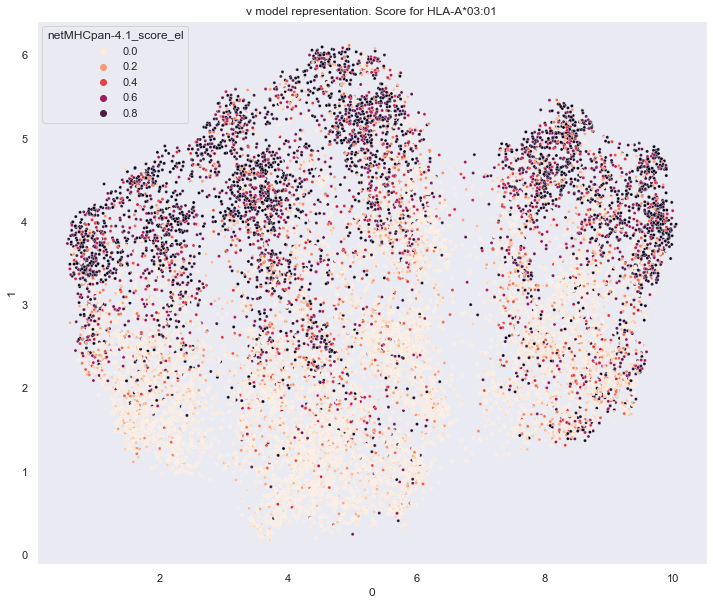

In [52]:
PREDICTOR_ALLELE = selected_alleles[1]
for model, perscoringallele_train_embeddings in per_model_type_perscoringallele_train_embeddings.items():
    print(f"model {model}")

    train_df = perscoringallele_train_embeddings[PREDICTOR_ALLELE]
    test_df = per_model_type_perscoringallele_test_embeddings[model][PREDICTOR_ALLELE]
    
    fig = make_scatter_plot_sns(train_df, title=f"{model} model representation. Score for {PREDICTOR_ALLELE}", hue_column=score)

In [25]:
PREDICTOR_ALLELE = selected_alleles[2]
for model, perscoringallele_train_embeddings in per_model_type_perscoringallele_train_embeddings.items():
    print(f"model {model}")

    train_df = perscoringallele_train_embeddings[PREDICTOR_ALLELE]
    test_df = per_model_type_perscoringallele_test_embeddings[model][PREDICTOR_ALLELE]
    
    fig = make_scatter_plot_sns(train_df, title=f"{model} model representation. Score for {PREDICTOR_ALLELE}", hue_column=score)

IndexError: list index out of range

model bw
model bwv
model v
Wall time: 2min 43s


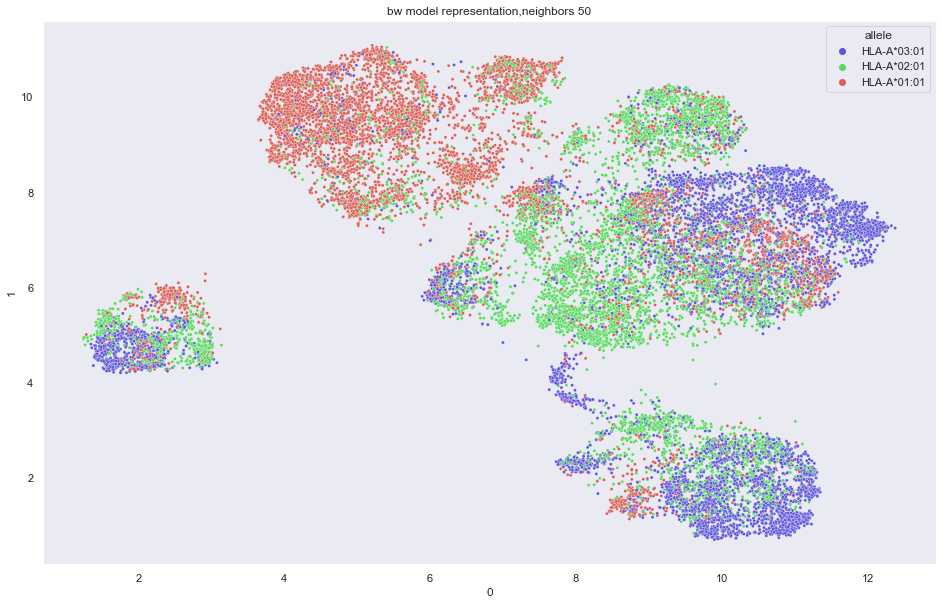

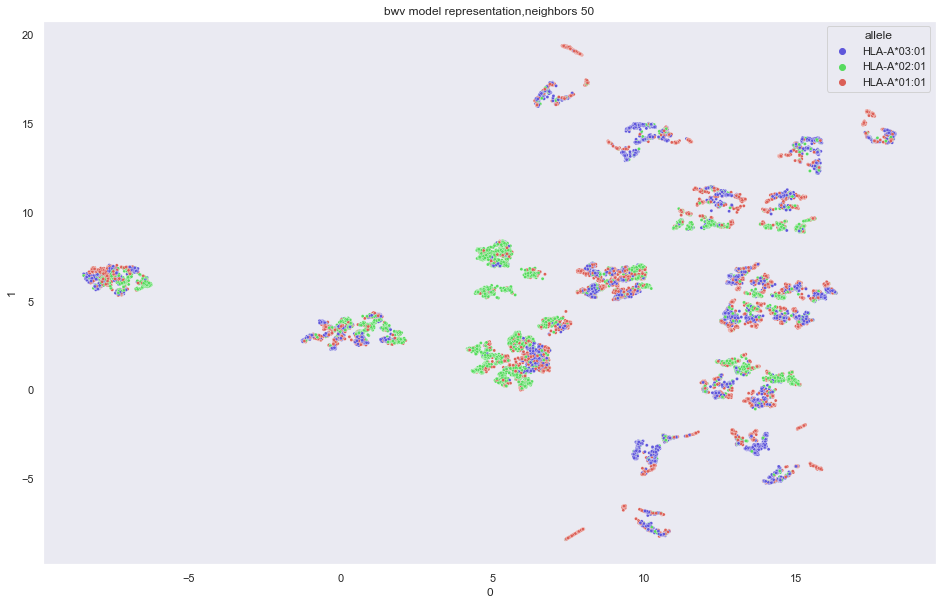

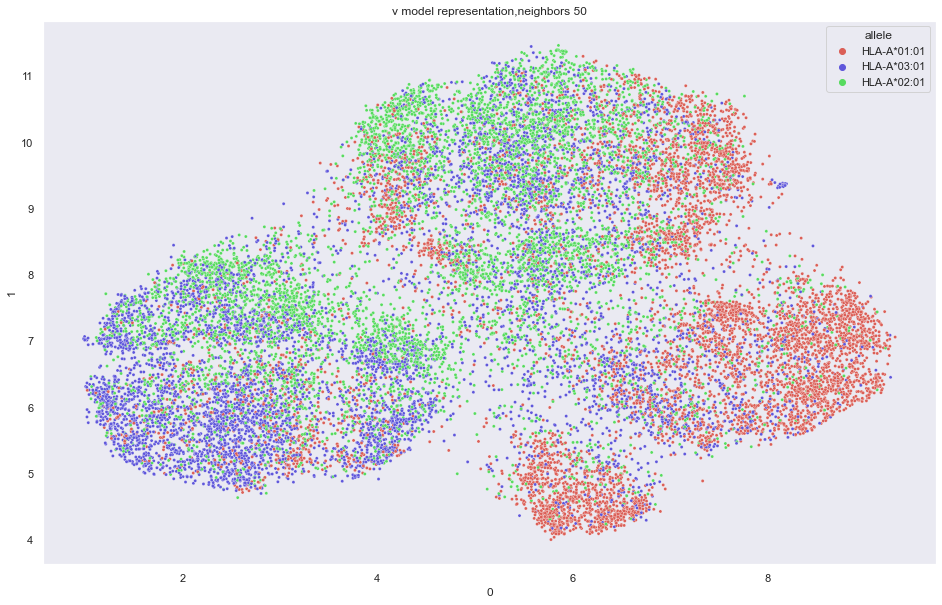

In [28]:
%%time
n = 50

train_embedding_bw = None
train_embedding_bwv = None
train_embedding_v= None

test_embedding_bw = None
test_embedding_bwv = None
test_embedding_v= None

for model, total_model_df in per_model_embedding_result.items():
    print(f"model {model}")
    train_df = total_model_df[total_model_df['dataset'] == f'Train_db']
    test_df = total_model_df[total_model_df['dataset'] == f'Test_db']

    train_data = train_df.drop(columns=["dataset", "peptide", "allele"],  errors='ignore')
    test_data = test_df.drop(columns=["dataset", "peptide", "allele"],  errors='ignore')
    reducer_b, scaler_b = get_reducer(train_data, n_neighbors=n)
    train_embedding = get_umap_embedding(reducer_b, scaler_b, train_data)
    train_embedding['allele'] = train_df['allele']
    train_embedding['dataset'] = train_df['dataset']
    train_embedding['length'] = train_embedding.index.str.len()
    test_embedding = get_umap_embedding(reducer_b, scaler_b, test_data)
    test_embedding['allele'] = test_df['allele']
    test_embedding['dataset'] = test_df['dataset']
    test_embedding['length'] = test_embedding.index.str.len()
    if model == "bw":
        train_embedding_bw = train_embedding
        test_embedding_bw = test_embedding
    elif model == 'bwv':
        train_embedding_bwv = train_embedding
        test_embedding_bwv = test_embedding
    elif model == 'v':
        train_embedding_v = train_embedding
        test_embedding_v = test_embedding

    fig = make_scatter_plot_sns(train_embedding, title=f"{model} model representation,neighbors {n}", hue_column='allele')

## Analyze motifs

In [ ]:
def make_logo(df, length=9):
    filtered = df[df['length'] == length]
    matrix = logomaker.alignment_to_matrix(filtered['peptide'].values)
    info_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='information')
    counts = df['allele'].value_counts()
    # prob_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='probability')
    ww_logo = logomaker.Logo(info_matrix, font_name='Arial Rounded MT Bold')
    ww_logo.ax.set_title(f" Allele counts: {counts}")

def select_rectangle(df, x1, x2, y1, y2):
    filtered_df = df[(df[0] > x1) & (df[0] < x2) & (df[1] > y1) & (df[1] < y2)]
    filtered_df['peptide'] = filtered_df.index
    return filtered_df


In [146]:
counts = train_embedding['allele'].value_counts()
counts

HLA-A*02:01    6666
HLA-A*03:01    6618
HLA-A*01:01    6589
Name: allele, dtype: int64

In [147]:
train_embedding = train_embedding_v
filtered_1 = select_rectangle(train_embedding, 0, 4, 0, 8)
filtered_2 = select_rectangle(train_embedding, 5, 7, 0, 5.2)

filtered_3 = select_rectangle(train_embedding, 6.1, 10, 5, 7.5)
filtered_4 = select_rectangle(train_embedding, 3, 8, 8, 15)

# #
# #
filtered_5 = select_rectangle(train_embedding, 4, 6, 5.5, 7.5)
filtered_6 = select_rectangle(train_embedding, 3.2, 4, 0, 7.5)
# #

C:\Users\denkl\AppData\Local\Temp/ipykernel_25764/2837600045.py:12: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  filtered_df['peptide'] = filtered_df.index


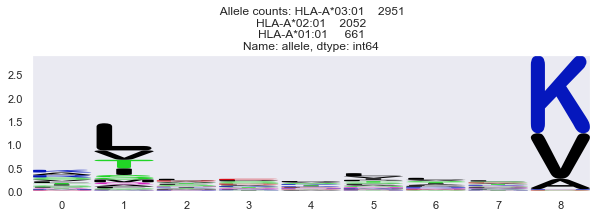

In [148]:
make_logo(filtered_1) # ... 

## Per length picture

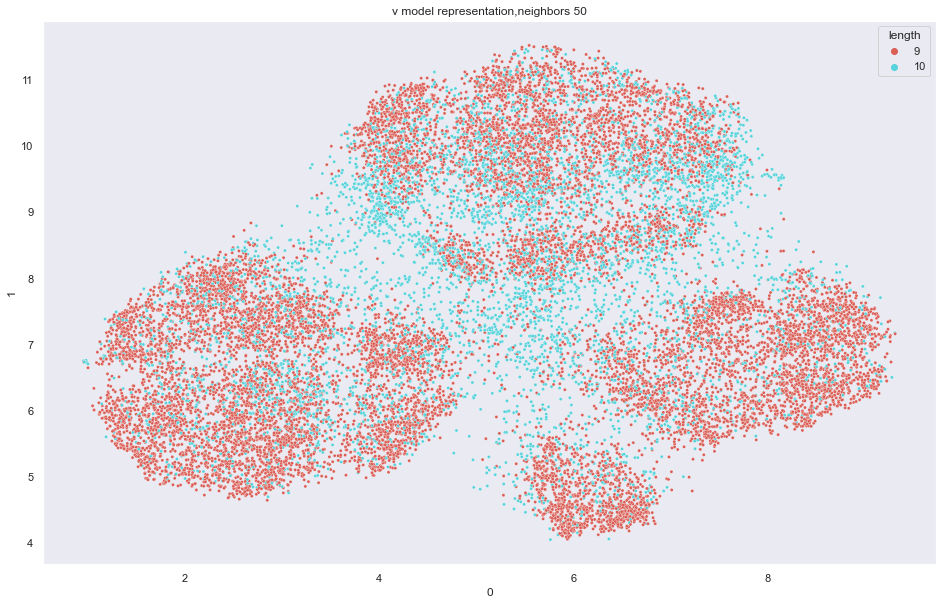

In [16]:
fig = make_scatter_plot_sns(train_embedding_v, title=f"{model} model representation,neighbors {n}", hue_column='length')

# Cluster result picture

# Some old alanysis just for history

# Test clustering approaches
## Run PCA  first (as it's suggested by K-Means)
### Get pca objects

In [36]:
per_name_representation_train['v']['db'].head()

,0,1,2,3,4,5,6,7,8,9,...,1992,1993,1994,1995,1996,1997,1998,1999,allele,label
PVSMTYLYNK,-0.767756,-1.088749,-1.088269,-1.136451,-1.110482,-1.126951,-0.866452,-0.985360,-0.735749,-0.874844,...,-1.145076,-1.230186,-1.147024,-0.874245,-1.095748,-1.457219,-1.120143,-1.239554,HLA-A*03:01,1
NYDLALKYF,-1.133209,-0.807913,-0.938645,-0.989824,-1.055381,-0.980324,-1.221345,-1.072828,-1.225003,-1.003204,...,-0.936420,-0.907656,-1.070104,-1.219688,-1.100022,-1.130287,-1.023211,-1.052718,HLA-A*01:01,0
TLKSFTVEK,-1.045980,-1.164910,-1.164430,-1.309880,-1.180526,-1.442628,-1.052648,-1.166878,-1.043307,-1.047711,...,-1.336272,-1.034953,-1.058531,-1.171488,-1.067980,-1.081329,-1.393245,-1.207510,HLA-A*03:01,1
AIFTDASTV,-1.062561,-0.941709,-0.941229,-0.655181,-0.822113,-0.645681,-1.069229,-1.062961,-1.006282,-0.945006,...,-0.834980,-0.810637,-0.835843,-0.821074,-0.946041,-1.074098,-0.576180,-0.962399,HLA-A*02:01,2
KLEYLAPSY,-1.049917,-0.929065,-0.928585,-0.919620,-0.980604,-1.052369,-0.925646,-1.050318,-1.060243,-0.932363,...,-1.184716,-0.893841,-0.919782,-1.054928,-1.011185,-1.143730,-1.156217,-1.098082,HLA-A*01:01,0


In [37]:
import sklearn
import seaborn as sns
from sklearn.decomposition import PCA
from collections import defaultdict

def get_pca(df_concat, n_components=2, target_cols=["allele","dataset", "label"],  whiten=True):
    X = df_concat.drop(columns=target_cols, errors='ignore').values
    pca = PCA(n_components=n_components, whiten=whiten)
    print(f"Shape {X.shape}")
    pca.fit(X)
    print('Explained variation per principal component: {}'.format(pca.explained_variance_ratio_))

    return pca

def get_pca_embedding(pca, data, target_cols=["allele","dataset", "label"]):
    X = data.drop(columns=target_cols, errors='ignore').values
    print(f"Shape of X {X.shape}")
    pca_result = pca.transform(X)
    df = pd.DataFrame(pca_result, index=data.index)
    return df




In [38]:
pca_bw = get_pca(pd.concat([per_name_representation_train['bw']['db']]), n_components=15)
pca_bwv = get_pca(pd.concat([per_name_representation_train['bwv']['db']]), n_components=15)
pca_v = get_pca(pd.concat([per_name_representation_train['v']['db']]), n_components=15)

Shape (20234, 1518)
Explained variation per principal component: [0.35394269 0.23587922 0.10104998 0.06258665 0.03244827 0.02813503
 0.02620156 0.02189285 0.01944591 0.01761573 0.012354   0.01153913
 0.01045792 0.00939453 0.00877473]
Shape (20234, 862)
Explained variation per principal component: [0.16391172 0.16114598 0.12877053 0.09399624 0.07988388 0.05734928
 0.05676028 0.04665017 0.03450371 0.03296763 0.03177579 0.02852508
 0.01591615 0.01296891 0.01113115]
Shape (20234, 2000)
Explained variation per principal component: [0.22852142 0.09858035 0.09364597 0.07301351 0.05111895 0.04725978
 0.04057294 0.0359668  0.03514807 0.029157   0.0243041  0.02106872
 0.02026886 0.01762114 0.01541918]


<AxesSubplot:>

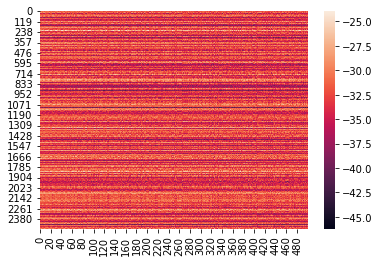

In [44]:
sns.heatmap(per_name_representation_test['bw']['db'].drop(columns=["allele"]).values)

<AxesSubplot:>

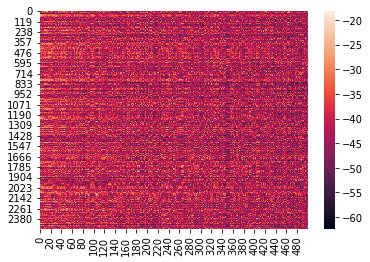

In [45]:
sns.heatmap(per_name_representation_test['bwv']['db'].drop(columns=["allele"]).values)

<AxesSubplot:>

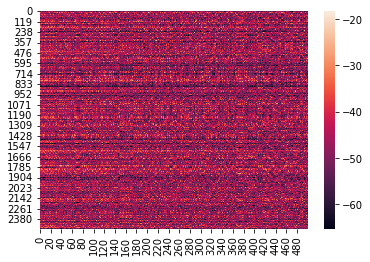

In [46]:
sns.heatmap(per_name_representation_test['v']['db'].drop(columns=["allele"]).values)

In [39]:
df = per_name_representation_train['bwv']['db'].drop(columns=["allele"]).copy().T

In [40]:
def collect_embeddings_with_pca_or_without(train_data, test_data, pca):
    columns_to_drop = ["dataset", "allele", "label"]
    if pca:
        train_embedding = get_pca_embedding(pca, train_data)
        test_embedding = get_pca_embedding(pca, test_data)
    else:
        train_embedding = train_data.drop(columns=columns_to_drop, errors='ignore')
        test_embedding = test_data.drop(columns=columns_to_drop, errors='ignore')
    if "allele" in train_data.columns:
        alleles_train = train_data['allele'].values
        alleles_test = test_data['allele'].values


    train_df = pd.DataFrame(train_embedding, index=train_data.index)
    train_df['dataset'] = 'Train'
    train_df['allele'] = alleles_train
    test_df = pd.DataFrame(test_embedding, index=test_data.index)
    test_df['dataset'] = 'Test'
    test_df['allele'] = alleles_test

    total_embedding = pd.concat([train_df, test_df])
    return total_embedding

In [41]:
def get_embedding_for_selected_models_using_pca(pca_bw, pca_bwv, pca_v):
    per_model_embedding_result= dict()
    for model_key in ['bw', 'bwv', 'v']:
        if model_key == 'bw':
            model_name = 'bw'
            pca = pca_bw
        elif model_key == 'bwv':
            model_name = 'bwv'
            pca = pca_bwv
        else:
            model_name = 'v'
            pca = pca_v

        train_repr = per_name_representation_train[model_name]['db'].copy()
        test_repr = per_name_representation_test[model_name]['db'].copy()
        total_embedding_db = collect_embeddings_with_pca_or_without(train_repr, test_repr, pca)
        total_embedding_db['dataset'] = total_embedding_db['dataset'] + '_db'

        total_embedding = pd.concat([total_embedding_db])
        per_model_embedding_result[model_key] = total_embedding
    return per_model_embedding_result


In [42]:
%%time
per_model_embedding_result_without_pca = get_embedding_for_selected_models_using_pca(None, None, None)
per_model_embedding_result = get_embedding_for_selected_models_using_pca(pca_bw, pca_bwv, pca_v)
# per_model_embedding_result_w = get_embedding_for_selected_models_using_pca(pca_b_w, pca_i_w)

Shape of X (20234, 1518)
Shape of X (5328, 1518)
Shape of X (20234, 862)
Shape of X (5328, 862)
Shape of X (20234, 2000)
Shape of X (5328, 2000)
Wall time: 8.75 s


In [47]:
per_model_embedding_result_without_pca['bw'].head()

,0,1,2,3,4,5,6,7,8,9,...,1992,1993,1994,1995,1996,1997,1998,1999,dataset,allele
ILSVSSFLFV,-0.364700,-0.381235,-0.367528,-0.378544,-0.371532,-0.351285,-0.366476,-0.361727,-0.388066,-0.349998,...,-0.438859,-0.464207,-0.405298,-0.479072,-0.384629,-0.439330,-0.419626,-0.406906,Train_db,HLA-A*02:01
YLGPRVCWL,-0.374002,-0.369963,-0.375464,-0.363823,-0.388018,-0.381692,-0.384524,-0.392517,-0.383978,-0.387589,...,-0.410033,-0.444902,-0.463343,-0.438130,-0.434872,-0.426301,-0.446673,-0.479272,Train_db,HLA-A*02:01
QTCLELERY,-0.389160,-0.398793,-0.392251,-0.411826,-0.405771,-0.385542,-0.391964,-0.351665,-0.415405,-0.394036,...,-0.476823,-0.481462,-0.469280,-0.492324,-0.443472,-0.422930,-0.480558,-0.461514,Train_db,HLA-A*01:01
YTIERIFNAK,-0.355430,-0.371965,-0.358258,-0.369274,-0.369446,-0.372350,-0.354239,-0.358270,-0.385980,-0.378247,...,-0.461023,-0.447076,-0.439204,-0.427925,-0.459893,-0.415830,-0.422495,-0.515466,Train_db,HLA-A*03:01
TAYGPNGMNK,-0.481032,-0.470816,-0.471870,-0.453353,-0.481343,-0.498497,-0.516707,-0.511324,-0.471128,-0.490691,...,-0.486136,-0.465521,-0.448926,-0.452600,-0.524882,-0.466095,-0.473271,-0.494837,Train_db,HLA-A*03:01


In [48]:
per_model_embedding_result_without_pca['bwv'].head()

,0,1,2,3,4,5,6,7,8,9,...,1992,1993,1994,1995,1996,1997,1998,1999,dataset,allele
ILSVSSFLFV,-0.375824,-0.458435,-0.438305,-0.462972,-0.399262,-0.375359,-0.307893,-0.396597,-0.424391,-0.526497,...,-0.690939,-0.748143,-0.797170,-0.690649,-0.696509,-0.549402,-0.656650,-0.580109,Train_db,HLA-A*02:01
YLGPRVCWL,-0.375384,-0.375884,-0.318415,-0.453251,-0.469359,-0.384728,-0.410935,-0.332883,-0.527944,-0.381633,...,-0.512078,-0.637890,-0.651993,-0.668445,-0.778125,-0.581005,-0.543768,-0.582657,Train_db,HLA-A*02:01
QTCLELERY,-0.490758,-0.573580,-0.576579,-0.549482,-0.576087,-0.584300,-0.417656,-0.526961,-0.325174,-0.647071,...,-0.732136,-0.849313,-0.788534,-0.601646,-0.662889,-0.646481,-0.783966,-0.643668,Train_db,HLA-A*01:01
YTIERIFNAK,-0.470495,-0.553105,-0.628358,-0.386680,-0.564470,-0.555947,-0.510853,-0.503916,-0.348079,-0.556329,...,-0.557415,-0.681102,-0.640245,-0.638204,-0.625053,-0.591918,-0.765382,-0.705399,Train_db,HLA-A*03:01
TAYGPNGMNK,-0.507488,-0.507989,-0.432012,-0.592135,-0.530785,-0.420424,-0.549782,-0.379522,-0.602320,-0.366064,...,-0.568634,-0.643238,-0.670440,-0.651408,-0.634305,-0.561511,-0.578042,-0.655989,Train_db,HLA-A*03:01


In [49]:
per_name_representation_train['bw']['db'].head()

,0,1,2,3,4,5,6,7,8,9,...,1991,1992,1993,1994,1995,1996,1997,1998,1999,allele
ILSVSSFLFV,-0.364700,-0.381235,-0.367528,-0.378544,-0.371532,-0.351285,-0.366476,-0.361727,-0.388066,-0.349998,...,-0.413016,-0.438859,-0.464207,-0.405298,-0.479072,-0.384629,-0.439330,-0.419626,-0.406906,HLA-A*02:01
YLGPRVCWL,-0.374002,-0.369963,-0.375464,-0.363823,-0.388018,-0.381692,-0.384524,-0.392517,-0.383978,-0.387589,...,-0.408443,-0.410033,-0.444902,-0.463343,-0.438130,-0.434872,-0.426301,-0.446673,-0.479272,HLA-A*02:01
QTCLELERY,-0.389160,-0.398793,-0.392251,-0.411826,-0.405771,-0.385542,-0.391964,-0.351665,-0.415405,-0.394036,...,-0.445261,-0.476823,-0.481462,-0.469280,-0.492324,-0.443472,-0.422930,-0.480558,-0.461514,HLA-A*01:01
YTIERIFNAK,-0.355430,-0.371965,-0.358258,-0.369274,-0.369446,-0.372350,-0.354239,-0.358270,-0.385980,-0.378247,...,-0.426974,-0.461023,-0.447076,-0.439204,-0.427925,-0.459893,-0.415830,-0.422495,-0.515466,HLA-A*03:01
TAYGPNGMNK,-0.481032,-0.470816,-0.471870,-0.453353,-0.481343,-0.498497,-0.516707,-0.511324,-0.471128,-0.490691,...,-0.458310,-0.486136,-0.465521,-0.448926,-0.452600,-0.524882,-0.466095,-0.473271,-0.494837,HLA-A*03:01


In [43]:
from collections import defaultdict
from sklearn.cluster import KMeans

def cluster_total_embedding(total_embedding_dfs, per_model_predictor):
    total_clustering_result = defaultdict(list)
    for m_key in total_embedding_dfs.keys():
        # print(f"model_key {m_key}")
        total_model_df =  total_embedding_dfs[m_key].copy()
        representation_df = total_model_df.drop(columns=["dataset", "peptide", "allele"],  errors='ignore')
        representation_df['label'] = per_model_predictor[m_key].predict(representation_df.values)
        representation_df['dataset'] = total_model_df['dataset']

        total_clustering_result[m_key] = representation_df

    return total_clustering_result

In [44]:
def clustering_experiment(total_embedding_df, cluster_counts):
    """
        Train will be used for training
        All other datasets will be fitted
    """

    per_cluster_count_result = dict()
    for cluster_count in cluster_counts:
        print(f"cluster_count {cluster_count}")
        # bw
        kmeans_bw = KMeans(n_clusters=cluster_count)
        total_model_df = total_embedding_df['bw'].copy()
        #extract train_data ensure no peptide columns
        train_df = total_model_df[total_model_df['dataset'] == f'Train_db']
        train_data = train_df.drop(columns=["dataset", "peptide", "allele"],  errors='ignore').values
        kmeans_bw.fit(train_data)
        # bwv
        kmeans_bwv = KMeans(n_clusters=cluster_count)
        total_model_df = total_embedding_df['bwv'].copy()
        #extract train_data ensure no peptide columns
        train_df = total_model_df[total_model_df['dataset'] == f'Train_db']
        train_data = train_df.drop(columns=["dataset", "peptide", "allele"],  errors='ignore').values
        kmeans_bwv.fit(train_data)

        # bwv
        kmeans_v = KMeans(n_clusters=cluster_count)
        total_model_df = total_embedding_df['v'].copy()
        #extract train_data ensure no peptide columns
        train_df = total_model_df[total_model_df['dataset'] == f'Train_db']
        train_data = train_df.drop(columns=["dataset", "peptide","allele"],  errors='ignore').values
        kmeans_v.fit(train_data)
        # # immmune model
        # total_model_df = total_embedding_df['mi'].copy()
        # kmeans_i = KMeans(n_clusters= cluster_count)
        # #extract train_data ensure no peptide columns
        # train_df =total_model_df[total_model_df['dataset'] == f'Train_di']
        # train_data = train_df.drop(columns=["dataset", "peptide"],  errors='ignore').values
        # kmeans_i.fit(train_data)

        total_clustering_result = cluster_total_embedding(total_embedding_df, {"bw":kmeans_bw , "bwv":kmeans_bwv, "v": kmeans_v})
        per_cluster_count_result[cluster_count] = total_clustering_result
    return per_cluster_count_result

In [45]:
cluster_counts = [2 , 4,  5]
per_cluster_count_result_pca = clustering_experiment(per_model_embedding_result, cluster_counts=cluster_counts)
per_cluster_count_result_repr = clustering_experiment(per_model_embedding_result_without_pca, cluster_counts=cluster_counts)

cluster_count 2
cluster_count 4
cluster_count 5
cluster_count 2
cluster_count 4
cluster_count 5


## Plot PCA plots

3    3794
0    3145
1    2168
2    1940
4     686
Name: label, dtype: int64


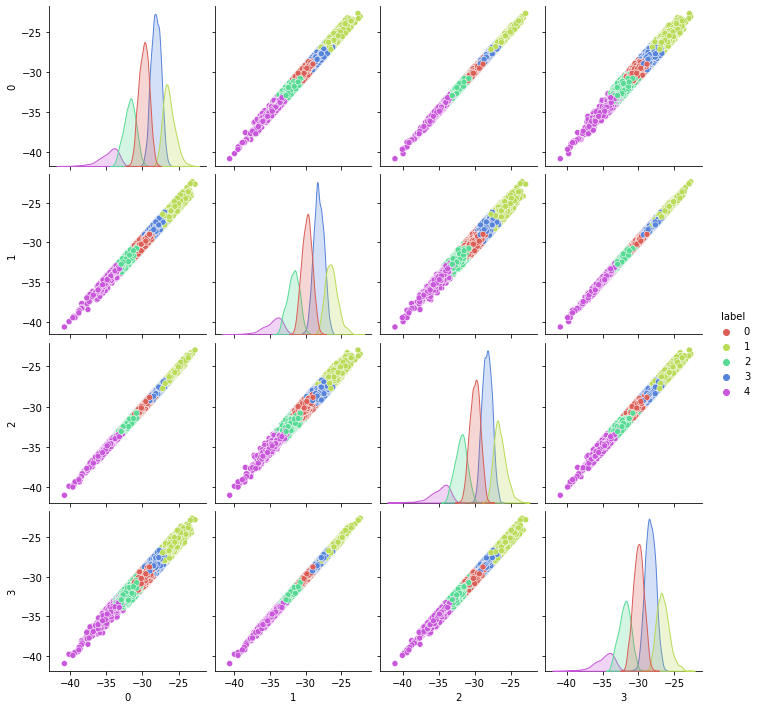

In [108]:
clusters_count = 5
sample_df = per_cluster_count_result_repr[clusters_count]['bw']
sample_df = sample_df.loc[~sample_df['dataset'].str.startswith('Generated')]
pca_first_components = sample_df[[0,1,2,3, 'label']].copy()
print(pca_first_components['label'].value_counts())
df = pca_first_components.reset_index(drop=True)
sns.pairplot(df, hue='label', palette=sns.color_palette("hls", clusters_count))


4    3045
0    2433
2    2372
1    2096
3    1787
Name: label, dtype: int64


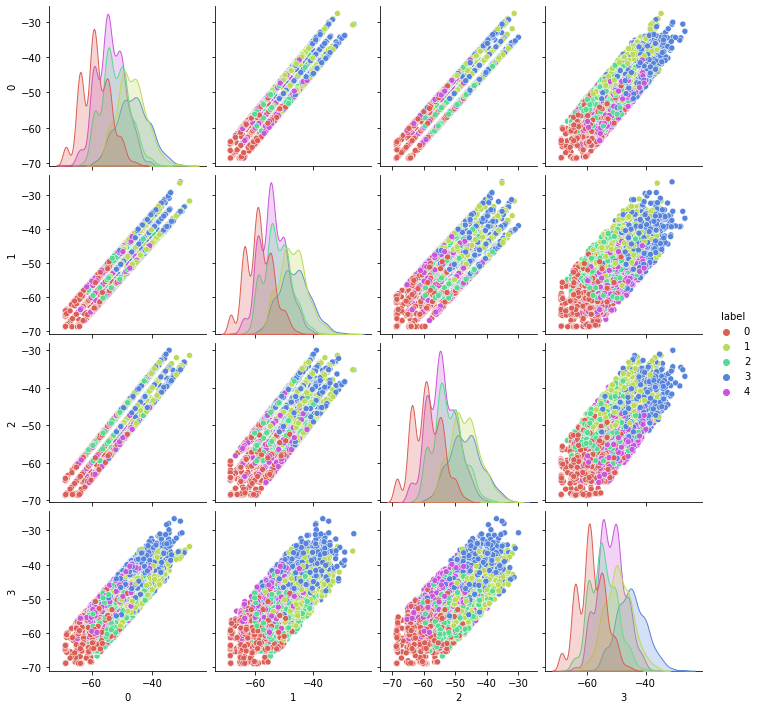

In [109]:
clusters_count = 5
sample_df = per_cluster_count_result_repr[clusters_count]['v']
sample_df = sample_df.loc[~sample_df['dataset'].str.startswith('Generated')]
pca_first_components = sample_df[[0,1,2,3, 'label']].copy()
print(pca_first_components['label'].value_counts())
df = pca_first_components.reset_index(drop=True)
sns.pairplot(df, hue='label', palette=sns.color_palette("hls", clusters_count))

2    3511
0    3262
3    2737
1    1207
4    1016
Name: label, dtype: int64


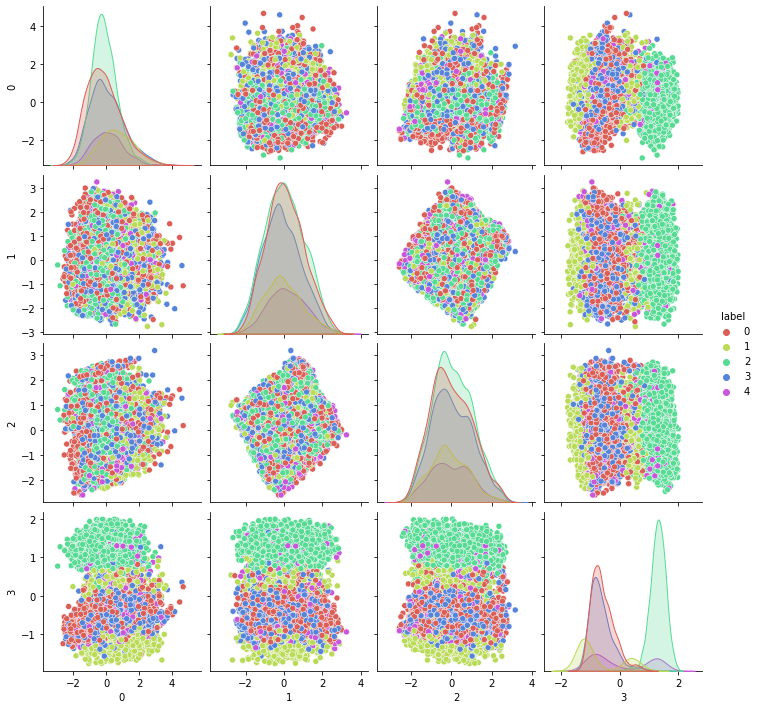

In [57]:
clusters_count = 5
sample_df = per_cluster_count_result_pca[clusters_count]['bw']
sample_df = sample_df.loc[~sample_df['dataset'].str.startswith('Generated')]
pca_first_components = sample_df[[0,1,2,3, 'label']].copy()
print(pca_first_components['label'].value_counts())
df = pca_first_components.reset_index(drop=True)
sns.pairplot(df, hue='label', palette=sns.color_palette("hls", clusters_count))

1    4276
4    3622
0    3598
3    3176
2    2798
Name: label, dtype: int64


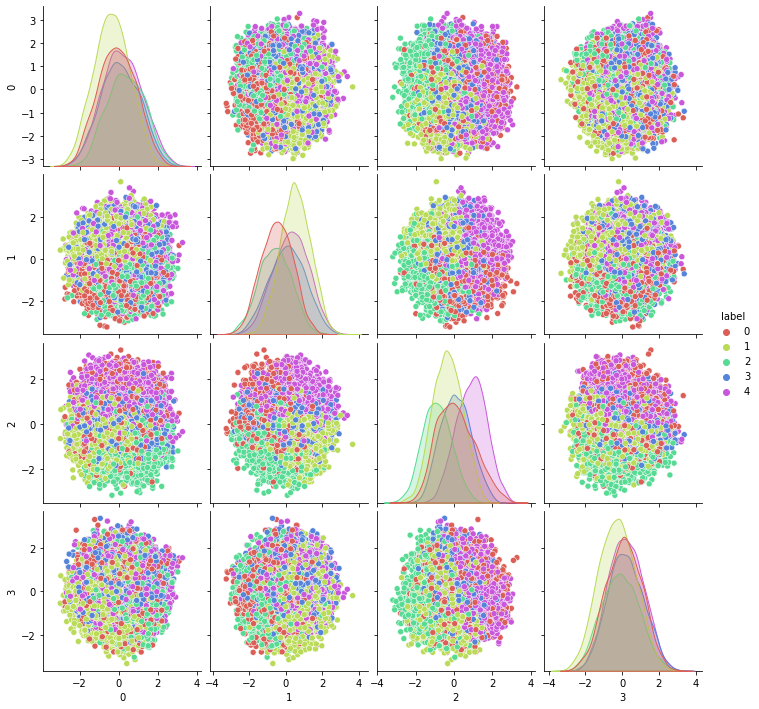

In [68]:
clusters_count = 5
sample_df = per_cluster_count_result_pca[clusters_count]['v']
sample_df = sample_df.loc[~sample_df['dataset'].str.startswith('Generated')]
pca_first_components = sample_df[[0,1,2,3, 'label']].copy()
print(pca_first_components['label'].value_counts())
df = pca_first_components.reset_index(drop=True)
sns.pairplot(df, hue='label', palette=sns.color_palette("hls", clusters_count))

1    4152
3    2817
4    2705
2    1567
0     492
Name: label, dtype: int64


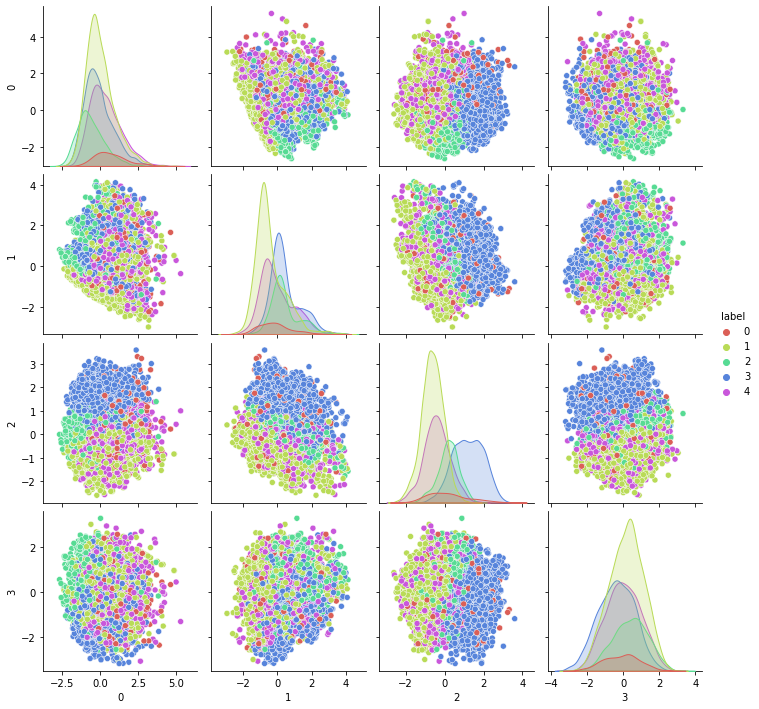

In [86]:
clusters_count = 5
sample_df = per_cluster_count_result_pca[clusters_count]['bwv']
sample_df = sample_df.loc[~sample_df['dataset'].str.startswith('Generated')]
pca_first_components = sample_df[[0,1,2,3, 'label']].copy()
print(pca_first_components['label'].value_counts())
df = pca_first_components.reset_index(drop=True)
sns.pairplot(df, hue='label', palette=sns.color_palette("hls", clusters_count))

In [96]:
df

,0,1,2,3,label
0,0.999295,0.387324,0.678455,-0.490383,3
1,0.108097,0.021062,0.669517,1.430231,3
2,-0.489513,0.130982,2.365413,-0.590073,0
3,0.476359,-0.651274,1.616374,-0.909632,0
4,0.215536,1.019187,-1.049684,0.503872,4
...,...,...,...,...,...
11728,1.826773,0.694532,-0.540280,0.434760,0
11729,1.655829,0.138762,-0.061199,2.225898,3
11730,-0.679647,-1.219310,-0.063222,1.409131,1
11731,0.944976,-0.191033,0.393523,1.156476,3
